# Heart Disease Patient Analysis (Final)
A data analyst portfolio project using Python (pandas), then Power BI and PowerPoint.

**Scenario.** A hospital cardiology department has records for 303 patients who were checked for heart disease. Management wants to use the data to improve **screening, triage and the use of diagnostic tests**.

This notebook answers **10 business problems**:

| # | Business problem |
|---|---|
| 1 | Can we trust the data? |
| 2 | How big is the problem, and who are our patients? |
| 3 | Which age groups are most affected? |
| 4 | Do men and women differ? |
| 5 | Can chest-pain type be used to triage patients? |
| 6 | Do routine checks (blood pressure, cholesterol, blood sugar, ECG) separate patients? |
| 7 | How useful is the exercise stress test? |
| 8 | How useful are imaging tests? |
| 9 | Which factors matter most? |
| 10 | Can we group patients into risk tiers? |

**Steps:** 1. Setup → 2. Load data → 3. Check and clean (Problem 1) → 4. New columns → 5–13. Problems 2–10 → 14. Export for Power BI → 15. Summary

## 1. Setup
Import the tools we need.

In [1]:
# Regular data analysis and plotting libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Statistics test used in Problem 9
from scipy.stats import chi2_contingency

# We want our plots to appear inside the notebook
%matplotlib inline

## 2. Load data

In [2]:
# Read the raw file (it lives in the data/raw folder)
df_raw = pd.read_csv("../data/raw/heart-disease.csv")
df_raw.shape   # (rows, columns)

(303, 14)

In [3]:
df_raw.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [5]:
df_raw.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


## 3. Business Problem 1: Can we trust the data?
We check four things:
1. Are there missing values?
2. Are there duplicate patients?
3. Are all codes inside their valid range?
4. Do the codes mean what the data dictionary says?

In [6]:
# Are there any missing values?
df_raw.isna().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [7]:
# Are there any duplicate rows?
df_raw.duplicated().sum()

np.int64(1)

In [8]:
# Show the duplicated patient (both copies)
df_raw[df_raw.duplicated(keep=False)]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
163,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1
164,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1


In [9]:
# 'ca' should be 0-3, so any 4 is invalid
df_raw["ca"].value_counts().sort_index()

ca
0    175
1     65
2     38
3     20
4      5
Name: count, dtype: int64

In [10]:
# 'thal' should be 1-3, so any 0 is invalid
df_raw["thal"].value_counts().sort_index()

thal
0      2
1     18
2    166
3    117
Name: count, dtype: int64

### 3.1 Do the codes mean what we think?
This file is a re-coded copy of the original **UCI Cleveland** file, where every code is documented: https://archive.ics.uci.edu/dataset/45/heart+disease

If we count each code in our file and compare it with the counts in the UCI file, we can see what each code really means.

In [11]:
# How many patients have each chest-pain code?
df_raw["cp"].value_counts().sort_index()

cp
0    143
1     50
2     87
3     23
Name: count, dtype: int64

In [12]:
# How many patients have each target value?
df_raw["target"].value_counts()

target
1    165
0    138
Name: count, dtype: int64

Next we compare these counts with the UCI file. They match to within 1 patient, and the difference is the duplicated row.

| Column | Code in our file | Patients | UCI meaning | UCI patients |
|---|---|---|---|---|
| cp | 0 | 143 | Asymptomatic (no chest pain) | 144 |
| cp | 1 | 50 | Atypical angina | 50 |
| cp | 2 | 87 | Non-anginal pain | 86 |
| cp | 3 | 23 | Typical angina | 23 |
| restecg | 0 | 147 | Left ventricular hypertrophy | 148 |
| restecg | 1 | 152 | Normal | 151 |
| restecg | 2 | 4 | ST-T wave abnormality | 4 |
| slope | 0 | 21 | Downsloping | 21 |
| slope | 1 | 140 | Flat | 140 |
| slope | 2 | 142 | Upsloping | 142 |
| thal | 1 / 2 / 3 | 18 / 166 / 117 | Fixed defect / Normal / Reversible defect | 18 / 166 / 117 |
| ca = 4, thal = 0 | | 5 / 2 | Missing values ('?') | 4 / 2 |
| target | 1 | 165 | **No** heart disease | 164 |
| target | 0 | 138 | Heart disease | 139 |

**This shows that `target = 1` means NO heart disease**, the reverse of the original data dictionary. Several other codes were also documented wrongly.

A quick sanity check: if `target = 1` meant disease, women would be more affected than men, which is the opposite of clinical evidence.

In [13]:
# Percentage of each sex with target = 0 and target = 1
pd.crosstab(df_raw["sex"], df_raw["target"], normalize="index") * 100

target,0,1
sex,,
0,25.000000,75.000000
1,55.072464,44.927536


Under the old reading, 75% of women (sex = 0) and 45% of men would have heart disease. That is clinically backwards, so the label must be reversed.

### 3.2 Clean the data
| Step | Action |
|---|---|
| 1 | Drop the duplicate row |
| 2 | Set the invalid codes (`ca = 4`, `thal = 0`) to missing |
| 3 | Create a correct outcome column: `heart_disease = 1 - target` |
| 4 | Replace the codes with readable labels |
| 5 | Rename the columns to plain English |

In [14]:
# Step 1: drop the duplicate row
df = df_raw.drop_duplicates().reset_index(drop=True)
df.shape

(302, 14)

In [15]:
# Step 2: invalid codes become missing (NaN)
df["ca"] = df["ca"].replace(4, np.nan)
df["thal"] = df["thal"].replace(0, np.nan)

# Step 3: correct outcome, so that 1 = heart disease
df["heart_disease"] = 1 - df["target"]
df["heart_disease"].value_counts()

heart_disease
0    164
1    138
Name: count, dtype: int64

In [16]:
# Step 4: replace codes with readable labels
df["sex"] = df["sex"].map({1: "Male", 0: "Female"})
df["cp"] = df["cp"].map({3: "Typical angina", 1: "Atypical angina", 2: "Non-anginal pain", 0: "Asymptomatic"})
df["fbs"] = df["fbs"].map({1: "Yes", 0: "No"})
df["restecg"] = df["restecg"].map({1: "Normal", 2: "ST-T abnormality", 0: "LV hypertrophy"})
df["exang"] = df["exang"].map({1: "Yes", 0: "No"})
df["slope"] = df["slope"].map({2: "Upsloping", 1: "Flat", 0: "Downsloping"})
df["thal"] = df["thal"].map({2: "Normal", 1: "Fixed defect", 3: "Reversible defect"}).fillna("Unknown")
df["diagnosis"] = df["heart_disease"].map({1: "Heart disease", 0: "No heart disease"})
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,heart_disease,diagnosis
0,63,Male,Typical angina,145,233,Yes,LV hypertrophy,150,No,2.3,Downsloping,0.0,Fixed defect,1,0,No heart disease
1,37,Male,Non-anginal pain,130,250,No,Normal,187,No,3.5,Downsloping,0.0,Normal,1,0,No heart disease
2,41,Female,Atypical angina,130,204,No,LV hypertrophy,172,No,1.4,Upsloping,0.0,Normal,1,0,No heart disease
3,56,Male,Atypical angina,120,236,No,Normal,178,No,0.8,Upsloping,0.0,Normal,1,0,No heart disease
4,57,Female,Asymptomatic,120,354,No,Normal,163,Yes,0.6,Upsloping,0.0,Normal,1,0,No heart disease


In [17]:
# Step 5: plain-English column names
df = df.rename(columns={"cp": "chest_pain_type",
                        "trestbps": "resting_bp",
                        "chol": "cholesterol",
                        "fbs": "high_fasting_sugar",
                        "restecg": "resting_ecg",
                        "thalach": "max_heart_rate",
                        "exang": "exercise_angina",
                        "oldpeak": "st_depression",
                        "slope": "st_slope",
                        "ca": "vessels_blocked",
                        "thal": "thallium_result",
                        "target": "original_target"})

# Give every patient an ID: P001, P002, ...
df.insert(0, "patient_id", ["P" + str(i).zfill(3) for i in range(1, len(df) + 1)])
df.head()

,patient_id,age,sex,chest_pain_type,resting_bp,cholesterol,high_fasting_sugar,resting_ecg,max_heart_rate,exercise_angina,st_depression,st_slope,vessels_blocked,thallium_result,original_target,heart_disease,diagnosis
0,P001,63,Male,Typical angina,145,233,Yes,LV hypertrophy,150,No,2.3,Downsloping,0.0,Fixed defect,1,0,No heart disease
1,P002,37,Male,Non-anginal pain,130,250,No,Normal,187,No,3.5,Downsloping,0.0,Normal,1,0,No heart disease
2,P003,41,Female,Atypical angina,130,204,No,LV hypertrophy,172,No,1.4,Upsloping,0.0,Normal,1,0,No heart disease
3,P004,56,Male,Atypical angina,120,236,No,Normal,178,No,0.8,Upsloping,0.0,Normal,1,0,No heart disease
4,P005,57,Female,Asymptomatic,120,354,No,Normal,163,Yes,0.6,Upsloping,0.0,Normal,1,0,No heart disease


### 3.3 Outliers
Next we look for extreme values. We **keep** them, because they are all medically possible.

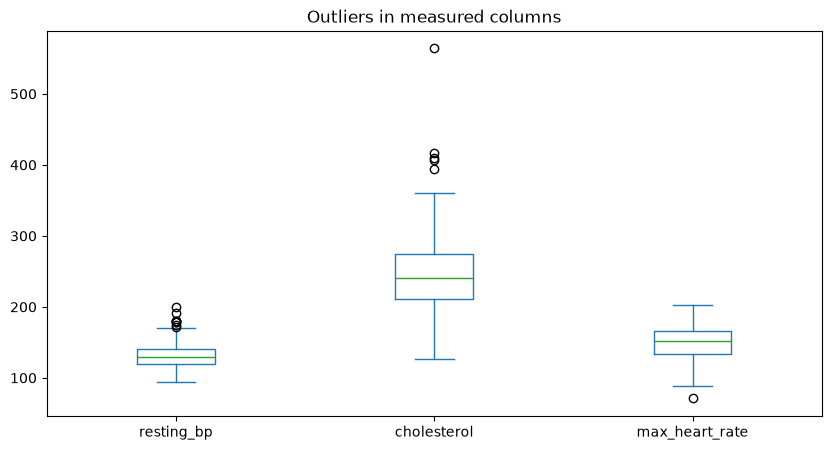

In [18]:
# Box plots of the measured columns
df[["resting_bp", "cholesterol", "max_heart_rate"]].plot(kind="box", figsize=(10, 5))
plt.title("Outliers in measured columns");

In [19]:
# Count outliers with the IQR rule (more than 1.5 x IQR outside the middle 50%)
numeric = ["age", "resting_bp", "cholesterol", "max_heart_rate", "st_depression"]
q1 = df[numeric].quantile(0.25)
q3 = df[numeric].quantile(0.75)
iqr = q3 - q1
outliers = ((df[numeric] < q1 - 1.5 * iqr) | (df[numeric] > q3 + 1.5 * iqr)).sum()
outliers

age               0
resting_bp        9
cholesterol       5
max_heart_rate    1
st_depression     5
dtype: int64

### Answer to Problem 1
**Yes, after cleaning. But the file could not be used as it came.**
* No missing values.
* 1 duplicate patient was removed, leaving **302 patients**.
* 6 invalid codes were set to *Unknown*.
* **The outcome label was reversed** (`target = 1` meant *no* disease). Without this check every conclusion would point the wrong way.
* 20 outliers were kept, because all are medically possible.

**Recommendation:** publish a validated data dictionary and add automatic checks before any report.

## 4. New columns (feature engineering)
Group the raw numbers into bands that are easier to read.

In [20]:
# Age groups
df["age_group"] = pd.cut(df["age"], bins=[0, 40, 50, 60, 70, 120], right=False,
                         labels=["Under 40", "40-49", "50-59", "60-69", "70+"])

# Blood pressure stages (American Heart Association)
df["bp_category"] = pd.cut(df["resting_bp"], bins=[0, 120, 130, 140, 400], right=False,
                           labels=["Normal (<120)", "Elevated (120-129)", "Stage 1 (130-139)", "Stage 2 (140+)"])

# Cholesterol bands
df["cholesterol_category"] = pd.cut(df["cholesterol"], bins=[0, 200, 240, 1000], right=False,
                                    labels=["Desirable (<200)", "Borderline (200-239)", "High (240+)"])

# Max heart rate bands
df["max_hr_band"] = pd.cut(df["max_heart_rate"], bins=[0, 120, 140, 160, 250], right=False,
                           labels=["Under 120", "120-139", "140-159", "160+"])

# ST depression bands
df["st_depression_band"] = pd.cut(df["st_depression"], bins=[-0.1, 0, 1, 2, 10],
                                  labels=["None (0)", "Mild (0.1-1)", "Moderate (1.1-2)", "Severe (>2)"])

# Vessels as text, so missing values show as "Unknown"
df["vessels_label"] = df["vessels_blocked"].map({0: "0 vessel(s)", 1: "1 vessel(s)", 2: "2 vessel(s)", 3: "3 vessel(s)"}).fillna("Unknown")

df[["age", "age_group", "resting_bp", "bp_category", "cholesterol", "cholesterol_category"]].head()

,age,age_group,resting_bp,bp_category,cholesterol,cholesterol_category
0,63,60-69,145,Stage 2 (140+),233,Borderline (200-239)
1,37,Under 40,130,Stage 1 (130-139),250,High (240+)
2,41,40-49,130,Stage 1 (130-139),204,Borderline (200-239)
3,56,50-59,120,Elevated (120-129),236,Borderline (200-239)
4,57,50-59,120,Elevated (120-129),354,High (240+)


## 5. Business Problem 2: How big is the problem, and who are our patients?

In [21]:
# How many patients have heart disease?
df["diagnosis"].value_counts()

diagnosis
No heart disease    164
Heart disease       138
Name: count, dtype: int64

In [22]:
# Overall disease rate (%). We compare every group with this number.
overall_rate = df["heart_disease"].mean() * 100
overall_rate

np.float64(45.6953642384106)

In [23]:
# Patient profile: median age and share of men
print("Median age:", df["age"].median())
print("Men (%):", round((df["sex"] == "Male").mean() * 100, 1))

Median age: 55.5
Men (%): 68.2


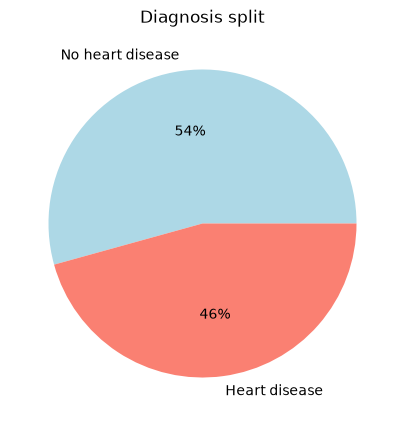

In [24]:
# Plot the diagnosis split
df["diagnosis"].value_counts().plot(kind="pie", autopct="%1.0f%%", colors=["lightblue", "salmon"], figsize=(5, 5))
plt.title("Diagnosis split")
plt.ylabel("");

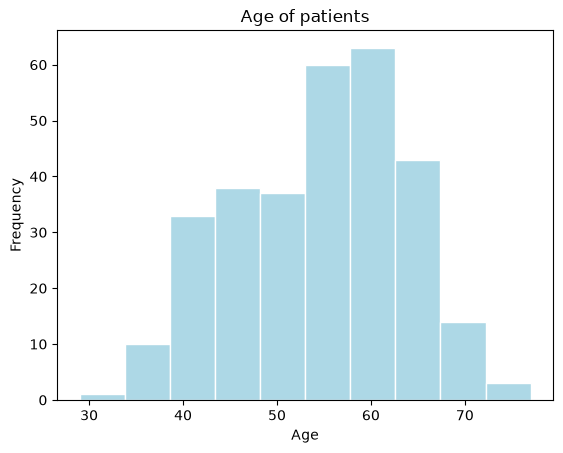

In [25]:
# Check the distribution of the age column with a histogram
df["age"].plot.hist(bins=10, color="lightblue", edgecolor="white")
plt.title("Age of patients")
plt.xlabel("Age");

### Answer to Problem 2
* **138 of 302 patients (46%) have heart disease**, almost half of everyone referred.
* The typical patient is a **man in his mid-50s** (median age 55.5; 68% men).

**Recommendation:** use 46% as the baseline. Groups well above it are a priority.

## 6. Business Problem 3: Which age groups are most affected?

In [26]:
# Compare age group with diagnosis
pd.crosstab(df["age_group"], df["diagnosis"])

diagnosis,Heart disease,No heart disease
age_group,,
Under 40,4,11
40-49,22,50
50-59,60,65
60-69,48,32
70+,4,6


In [27]:
# Disease rate (%) for each age group
age_rate = df.groupby("age_group", observed=True)["heart_disease"].mean() * 100
age_rate

age_group
Under 40    26.666667
40-49       30.555556
50-59       48.000000
60-69       60.000000
70+         40.000000
Name: heart_disease, dtype: float64

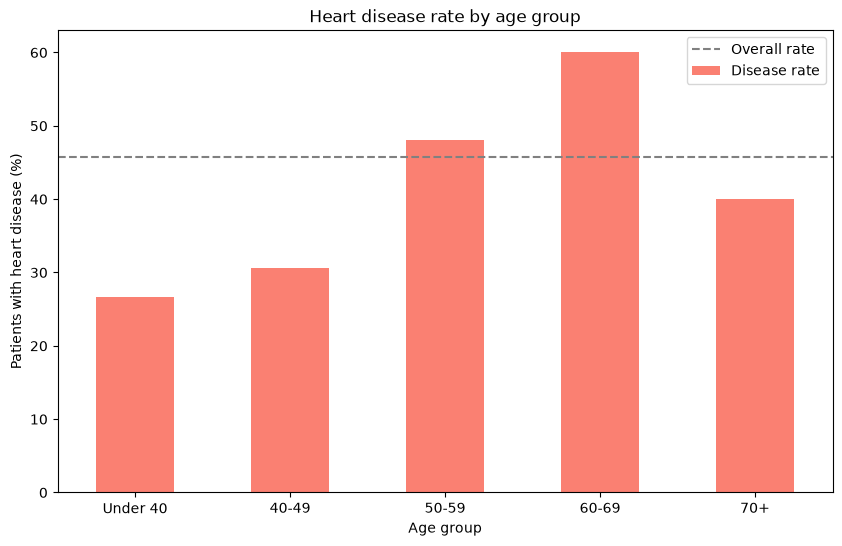

In [28]:
# Create a plot of the disease rate by age group
age_rate.plot(kind="bar", color="salmon", figsize=(10, 6))
plt.axhline(overall_rate, color="grey", linestyle="--", label="Overall rate")
plt.title("Heart disease rate by age group")
plt.xlabel("Age group")
plt.ylabel("Patients with heart disease (%)")
plt.legend(["Overall rate", "Disease rate"])
plt.xticks(rotation=0);

In [29]:
# Average age of patients with and without heart disease
df.groupby("diagnosis")["age"].median()

diagnosis
Heart disease       58.0
No heart disease    52.0
Name: age, dtype: float64

### Answer to Problem 3
* The disease rate **rises with age**: 27% under 40, 31% at 40–49, 48% at 50–59 and **60% at 60–69**.
* Patients with heart disease are older (median **58 against 52**).
* The 70+ group has only 10 patients, which is too few to read much into.

**Recommendation:** start routine screening at **age 50**.

## 7. Business Problem 4: Do men and women differ?

In [30]:
# Compare sex with diagnosis
pd.crosstab(df["sex"], df["diagnosis"])

diagnosis,Heart disease,No heart disease
sex,,
Female,24,72
Male,114,92


In [31]:
# Disease rate (%) for each sex
sex_rate = df.groupby("sex")["heart_disease"].mean() * 100
sex_rate

sex
Female    25.000000
Male      55.339806
Name: heart_disease, dtype: float64

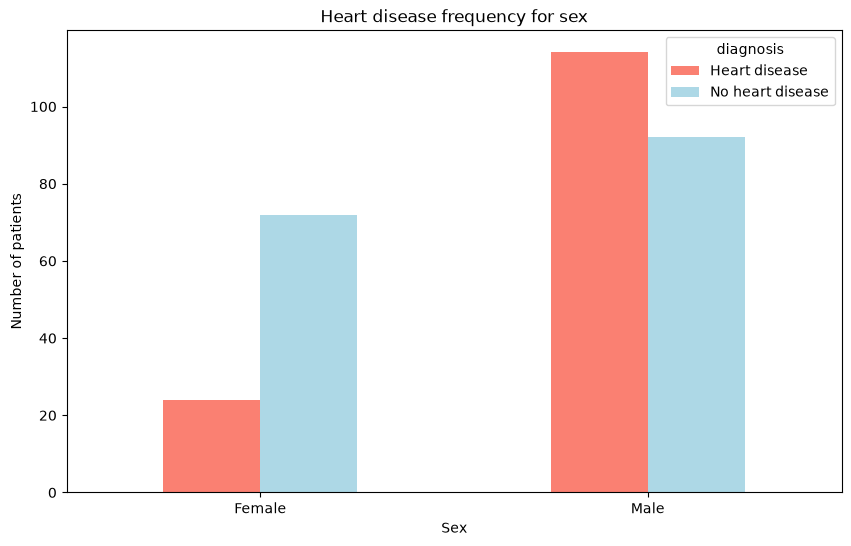

In [32]:
# Create a plot of crosstab
pd.crosstab(df["sex"], df["diagnosis"]).plot(kind="bar", figsize=(10, 6), color=["salmon", "lightblue"])
plt.title("Heart disease frequency for sex")
plt.xlabel("Sex")
plt.ylabel("Number of patients")
plt.xticks(rotation=0);

In [33]:
# Disease rate (%) by sex AND age group
sex_age = pd.crosstab(df["sex"], df["age_group"], values=df["heart_disease"], aggfunc="mean") * 100
sex_age.round(0)

age_group,Under 40,40-49,50-59,60-69,70+
sex,,,,,
Female,0.0,5.0,29.0,39.0,0.0
Male,40.0,40.0,55.0,74.0,80.0


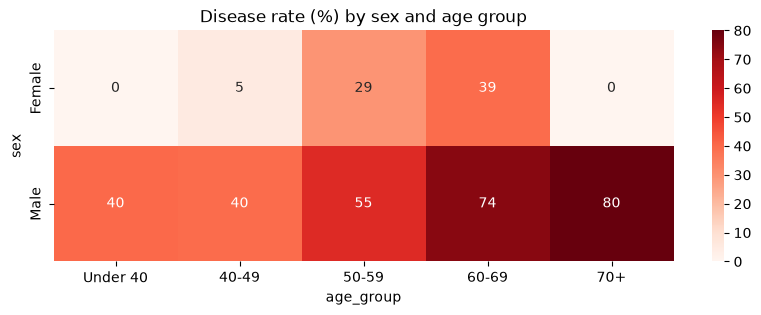

In [34]:
# Show it as a heatmap
plt.figure(figsize=(10, 3))
sns.heatmap(sex_age, annot=True, fmt=".0f", cmap="Reds")
plt.title("Disease rate (%) by sex and age group");

### Answer to Problem 4
* **Men 55% against women 25%**: men are more than twice as likely to have heart disease.
* The gap holds at every age. Men reach 74% at 60–69.
* Only 96 of the 302 patients are women.

**Recommendation:** screen men from age 40–45 and women from 50. Check whether women with symptoms are being under-referred.

## 8. Business Problem 5: Can chest-pain type be used to triage patients?

In [35]:
# Compare chest-pain type with diagnosis
pd.crosstab(df["chest_pain_type"], df["diagnosis"])

diagnosis,Heart disease,No heart disease
chest_pain_type,,
Asymptomatic,104,39
Atypical angina,9,41
Non-anginal pain,18,68
Typical angina,7,16


In [36]:
# Disease rate (%) for each chest-pain type, in a logical order
cp_order = ["Typical angina", "Atypical angina", "Non-anginal pain", "Asymptomatic"]
cp_rate = df.groupby("chest_pain_type")["heart_disease"].mean().reindex(cp_order) * 100
cp_rate

chest_pain_type
Typical angina      30.434783
Atypical angina     18.000000
Non-anginal pain    20.930233
Asymptomatic        72.727273
Name: heart_disease, dtype: float64

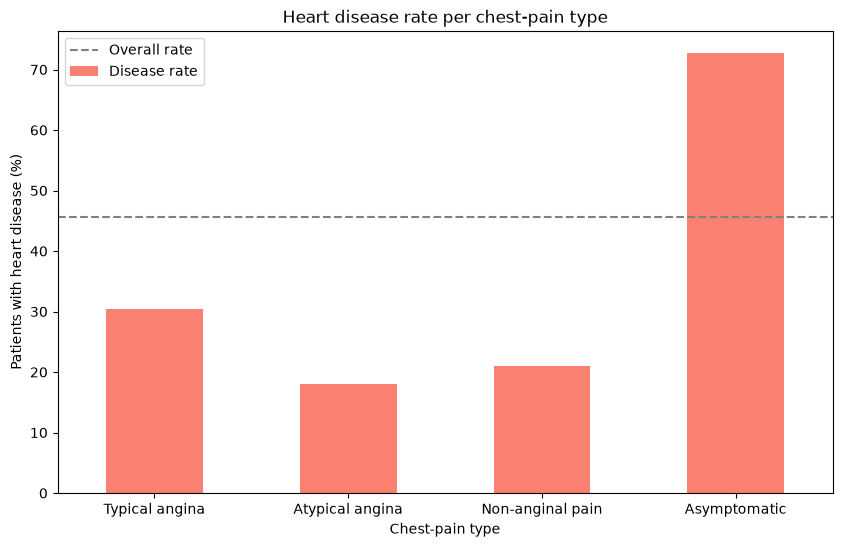

In [37]:
cp_rate.plot(kind="bar", color="salmon", figsize=(10, 6))
plt.axhline(overall_rate, color="grey", linestyle="--", label="Overall rate")
plt.title("Heart disease rate per chest-pain type")
plt.xlabel("Chest-pain type")
plt.ylabel("Patients with heart disease (%)")
plt.legend(["Overall rate", "Disease rate"])
plt.xticks(rotation=0);

### Answer to Problem 5
* Patients with **no chest pain (asymptomatic) have the highest rate: 73%**.
* Classic typical angina is only 30%. Atypical and non-anginal pain are about 18–21%.

**Recommendation:** a rule of "chest pain = urgent" would miss most cases. **Fast-track silent (asymptomatic) patients** for further tests.

## 9. Business Problem 6: Do routine checks separate patients?
The routine checks are blood pressure, cholesterol, fasting blood sugar and the resting ECG.

In [38]:
# Disease rate (%) for each routine check
bp_rate = df.groupby("bp_category", observed=True)["heart_disease"].mean() * 100
chol_rate = df.groupby("cholesterol_category", observed=True)["heart_disease"].mean() * 100
sugar_rate = df.groupby("high_fasting_sugar")["heart_disease"].mean() * 100
ecg_rate = df.groupby("resting_ecg")["heart_disease"].mean().reindex(["Normal", "ST-T abnormality", "LV hypertrophy"]) * 100

print(bp_rate.round(1), "\n")
print(chol_rate.round(1), "\n")
print(sugar_rate.round(1), "\n")
print(ecg_rate.round(1))

bp_category
Normal (<120)         38.3
Elevated (120-129)    46.7
Stage 1 (130-139)     38.6
Stage 2 (140+)        54.6
Name: heart_disease, dtype: float64 

cholesterol_category
Desirable (<200)        40.8
Borderline (200-239)    39.8
High (240+)             51.0
Name: heart_disease, dtype: float64 

high_fasting_sugar
No     45.1
Yes    48.9
Name: heart_disease, dtype: float64 

resting_ecg
Normal              37.1
ST-T abnormality    75.0
LV hypertrophy      53.7
Name: heart_disease, dtype: float64


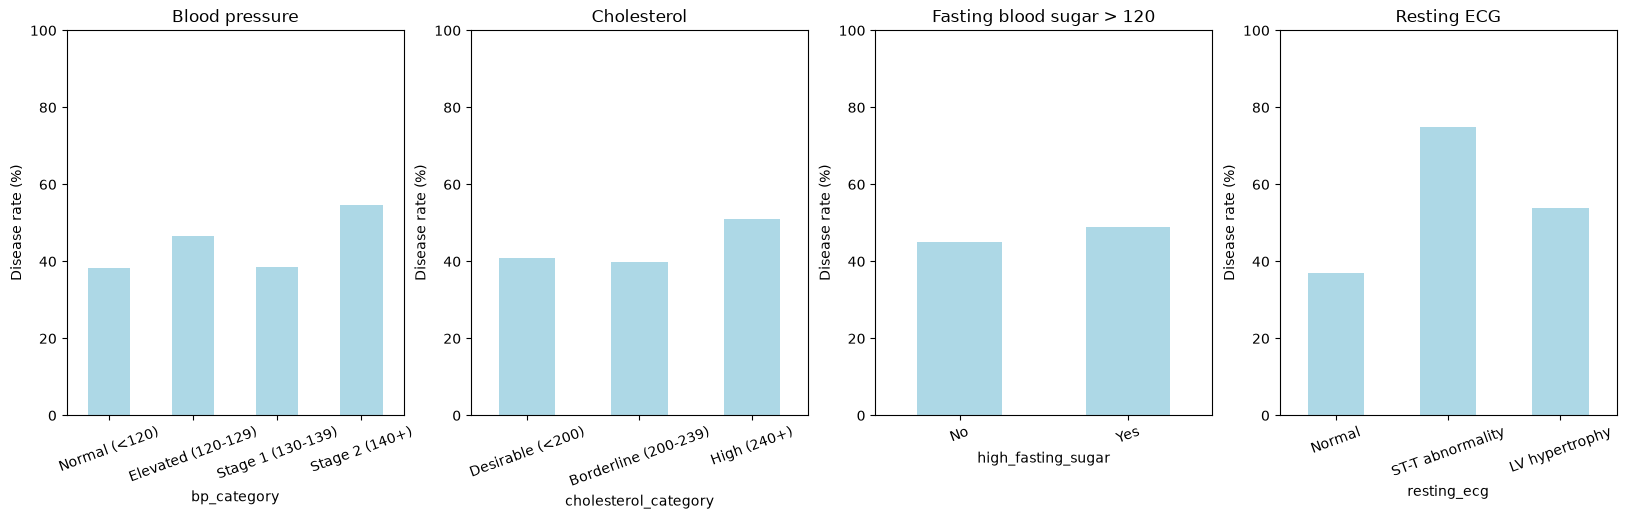

In [39]:
# Plot the four routine checks side by side
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
bp_rate.plot(kind="bar", ax=axes[0], color="lightblue", title="Blood pressure")
chol_rate.plot(kind="bar", ax=axes[1], color="lightblue", title="Cholesterol")
sugar_rate.plot(kind="bar", ax=axes[2], color="lightblue", title="Fasting blood sugar > 120")
ecg_rate.plot(kind="bar", ax=axes[3], color="lightblue", title="Resting ECG")
for ax in axes:
    ax.set_ylim(0, 100)
    ax.set_ylabel("Disease rate (%)")
    ax.tick_params(axis="x", rotation=20)

In [40]:
# Average blood pressure and cholesterol for each group
df.groupby("diagnosis")[["resting_bp", "cholesterol"]].mean()

,resting_bp,cholesterol
diagnosis,,
Heart disease,134.398551,251.086957
No heart disease,129.250000,242.640244


### Answer to Problem 6
**Only weakly. Routine checks are poor at separating patients on their own.**
* Blood pressure: Stage 2 is 55% against 38% for normal, and the pattern is not consistent.
* Cholesterol: high is 51% against 41% for desirable. The averages differ only slightly (251 against 243).
* Fasting blood sugar: almost no difference (49% against 45%).
* Resting ECG: a modest signal (normal 37%, LV hypertrophy 54%).

**Recommendation:** keep routine checks for prevention, but **don't use them to decide who gets referred**.

## 10. Business Problem 7: How useful is the exercise stress test?
The stress test measures max heart rate, chest pain during exercise, ST depression and ST slope.

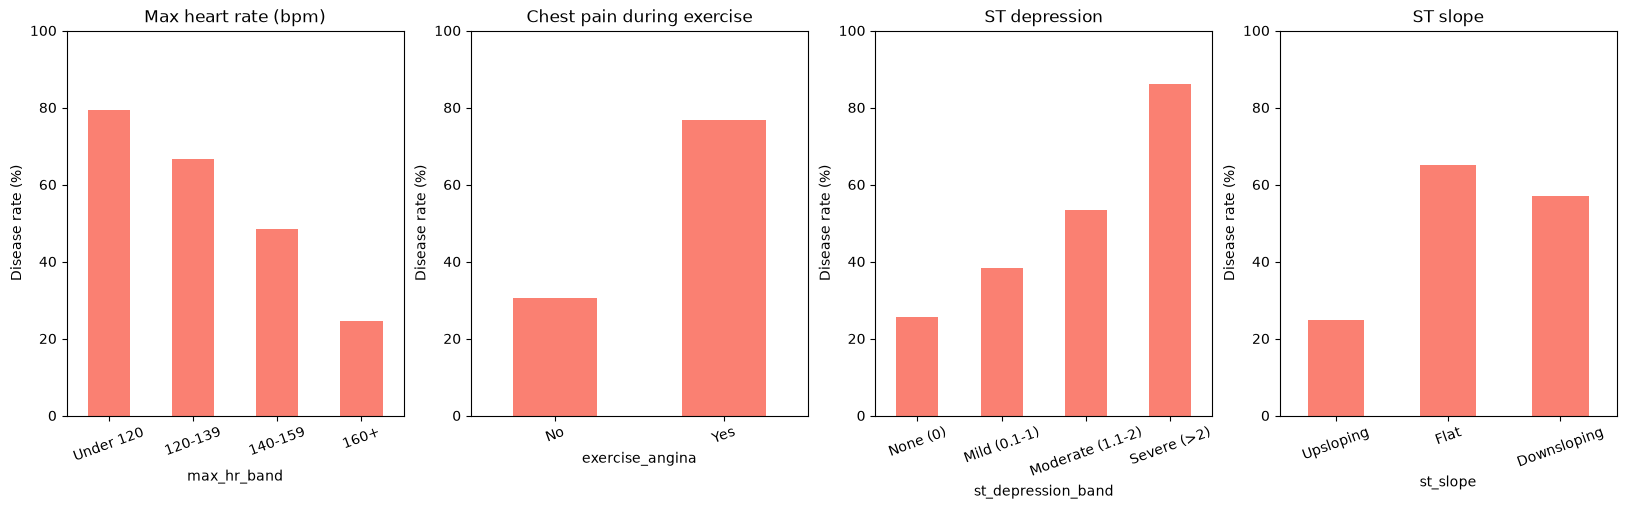

In [41]:
# Disease rate (%) for each stress-test result
hr_rate = df.groupby("max_hr_band", observed=True)["heart_disease"].mean() * 100
angina_rate = df.groupby("exercise_angina")["heart_disease"].mean() * 100
st_rate = df.groupby("st_depression_band", observed=True)["heart_disease"].mean() * 100
slope_rate = df.groupby("st_slope")["heart_disease"].mean().reindex(["Upsloping", "Flat", "Downsloping"]) * 100

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
hr_rate.plot(kind="bar", ax=axes[0], color="salmon", title="Max heart rate (bpm)")
angina_rate.plot(kind="bar", ax=axes[1], color="salmon", title="Chest pain during exercise")
st_rate.plot(kind="bar", ax=axes[2], color="salmon", title="ST depression")
slope_rate.plot(kind="bar", ax=axes[3], color="salmon", title="ST slope")
for ax in axes:
    ax.set_ylim(0, 100)
    ax.set_ylabel("Disease rate (%)")
    ax.tick_params(axis="x", rotation=20)

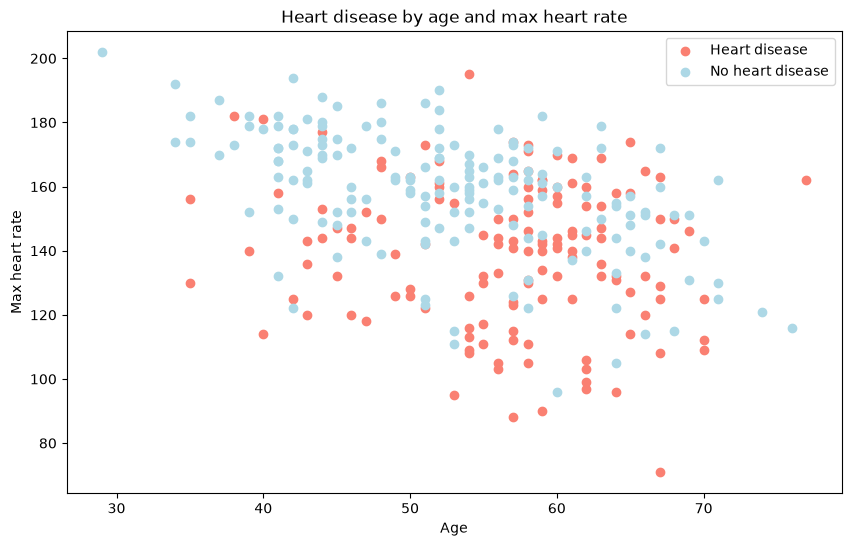

In [42]:
# Create a scatter plot of age vs. max heart rate
plt.figure(figsize=(10, 6))

# Scatter with positive examples (heart disease)
plt.scatter(df.age[df.heart_disease == 1], df.max_heart_rate[df.heart_disease == 1], c="salmon")

# Scatter with negative examples (no heart disease)
plt.scatter(df.age[df.heart_disease == 0], df.max_heart_rate[df.heart_disease == 0], c="lightblue")

plt.title("Heart disease by age and max heart rate")
plt.xlabel("Age")
plt.ylabel("Max heart rate")
plt.legend(["Heart disease", "No heart disease"]);

### Answer to Problem 7
**Very useful. All four measures show strong patterns.**
* Max heart rate under 120: 79% have disease. At 160+: 25%.
* Chest pain during exercise: 77% with it, 31% without.
* ST depression: rises from 26% (none) to **86% (severe)**.
* Flat or downsloping ST slope: 57–65%, against 25% for upsloping.

**Recommendation:** use the stress test **early**. It is the best-value mid-cost test.

## 11. Business Problem 8: How useful are imaging tests?
Fluoroscopy counts narrowed vessels (0–3). The thallium scan shows blood flow to the heart.

In [43]:
# Disease rate (%) by number of narrowed vessels
vessels_rate = df.groupby("vessels_label")["heart_disease"].mean() * 100
vessels_rate

vessels_label
0 vessel(s)    25.714286
1 vessel(s)    67.692308
2 vessel(s)    81.578947
3 vessel(s)    85.000000
Unknown        25.000000
Name: heart_disease, dtype: float64

In [44]:
# Disease rate (%) by thallium scan result
thal_rate = df.groupby("thallium_result")["heart_disease"].mean().reindex(["Normal", "Fixed defect", "Reversible defect", "Unknown"]) * 100
thal_rate

thallium_result
Normal               21.818182
Fixed defect         66.666667
Reversible defect    76.068376
Unknown              50.000000
Name: heart_disease, dtype: float64

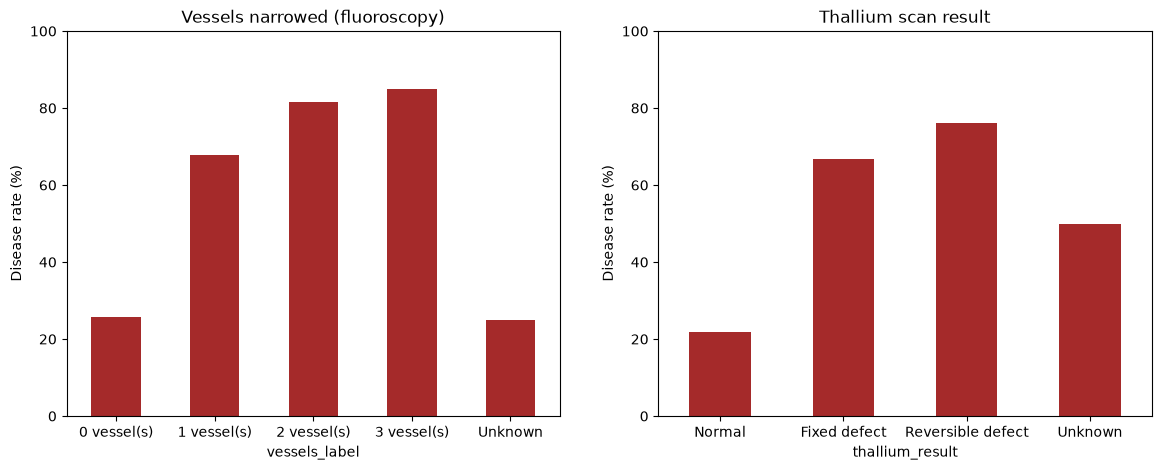

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
vessels_rate.plot(kind="bar", ax=axes[0], color="brown", title="Vessels narrowed (fluoroscopy)")
thal_rate.plot(kind="bar", ax=axes[1], color="brown", title="Thallium scan result")
for ax in axes:
    ax.set_ylim(0, 100)
    ax.set_ylabel("Disease rate (%)")
    ax.tick_params(axis="x", rotation=0)

### Answer to Problem 8
**Imaging gives the strongest signal of all.**
* Narrowed vessels: 26% at 0, 68% at 1, 82% at 2, **85% at 3**.
* Thallium scan: normal 22%, **reversible defect 76%**, fixed defect 67%.

**Recommendation:** imaging is expensive, so **use it for patients already flagged** by symptoms or the stress test.

## 12. Business Problem 9: Which factors matter most?
We compare every factor on one scale with **Cramér's V**. It runs from 0 (no link with the diagnosis) to 1 (a perfect link).
* **Rate gap:** the difference between the highest and lowest disease rate across a factor's groups.
* **p-value:** from a chi-square test. Below 0.05 means the difference is unlikely to be chance.

In [46]:
# Each factor: (name, column, type of test)
factors = [("Thallium scan", "thallium_result", "Imaging"),
           ("Vessels narrowed", "vessels_label", "Imaging"),
           ("Chest-pain type", "chest_pain_type", "Symptoms"),
           ("Exercise angina", "exercise_angina", "Stress test"),
           ("ST depression", "st_depression_band", "Stress test"),
           ("Max heart rate", "max_hr_band", "Stress test"),
           ("ST slope", "st_slope", "Stress test"),
           ("Sex", "sex", "Demographics"),
           ("Age group", "age_group", "Demographics"),
           ("Resting ECG", "resting_ecg", "Routine check"),
           ("Blood pressure", "bp_category", "Routine check"),
           ("Cholesterol", "cholesterol_category", "Routine check"),
           ("Fasting blood sugar", "high_fasting_sugar", "Routine check")]

results = []
for name, col, test_type in factors:
    data = df[df[col].astype(str) != "Unknown"]               # leave out unknown values
    table = pd.crosstab(data[col], data["heart_disease"])     # counts per group
    chi2, p_value, dof, expected = chi2_contingency(table)    # chi-square test
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

    rates = data.groupby(col, observed=True)["heart_disease"].agg(["mean", "count"])
    rates = (rates[rates["count"] >= 10]["mean"] * 100).round(1)   # ignore tiny groups (< 10 patients)
    rate_gap = rates.max() - rates.min()

    results.append([name, test_type, round(cramers_v, 2), round(rate_gap, 1), p_value])

ranking = pd.DataFrame(results, columns=["factor", "test_type", "cramers_v", "rate_gap_pts", "p_value"])
ranking = ranking.sort_values("cramers_v", ascending=False).reset_index(drop=True)
ranking["significant"] = np.where(ranking["p_value"] < 0.05, "Yes", "No")
ranking.index = ranking.index + 1    # rank starts at 1
ranking

,factor,test_type,cramers_v,rate_gap_pts,p_value,significant
1,Thallium scan,Imaging,0.53,54.3,4.251403e-19,Yes
2,Chest-pain type,Symptoms,0.52,54.7,1.892684e-17,Yes
3,Vessels narrowed,Imaging,0.49,59.3,1.010088e-15,Yes
4,Exercise angina,Stress test,0.43,46.3,9.556466e-14,Yes
5,ST depression,Stress test,0.42,60.5,2.486390e-11,Yes
6,Max heart rate,Stress test,0.39,54.8,5.310594e-10,Yes
7,ST slope,Stress test,0.39,40.2,6.577783e-11,Yes
8,Sex,Demographics,0.28,30.3,1.550855e-06,Yes
9,Age group,Demographics,0.23,33.3,3.249459e-03,Yes
10,Resting ECG,Routine check,0.18,16.6,7.713053e-03,Yes


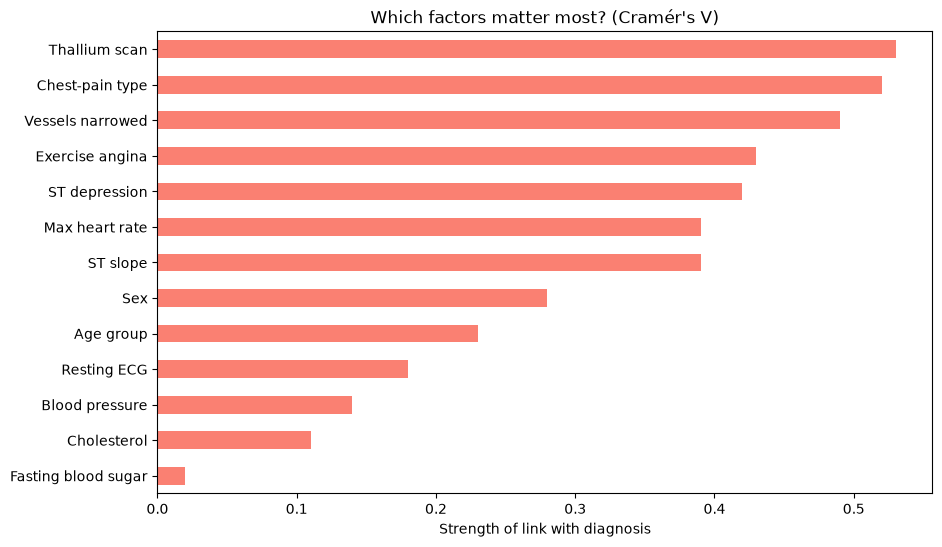

In [47]:
# Plot the ranking
ranking.sort_values("cramers_v").plot(kind="barh", x="factor", y="cramers_v", color="salmon", legend=False, figsize=(10, 6))
plt.title("Which factors matter most? (Cramér's V)")
plt.xlabel("Strength of link with diagnosis")
plt.ylabel("");

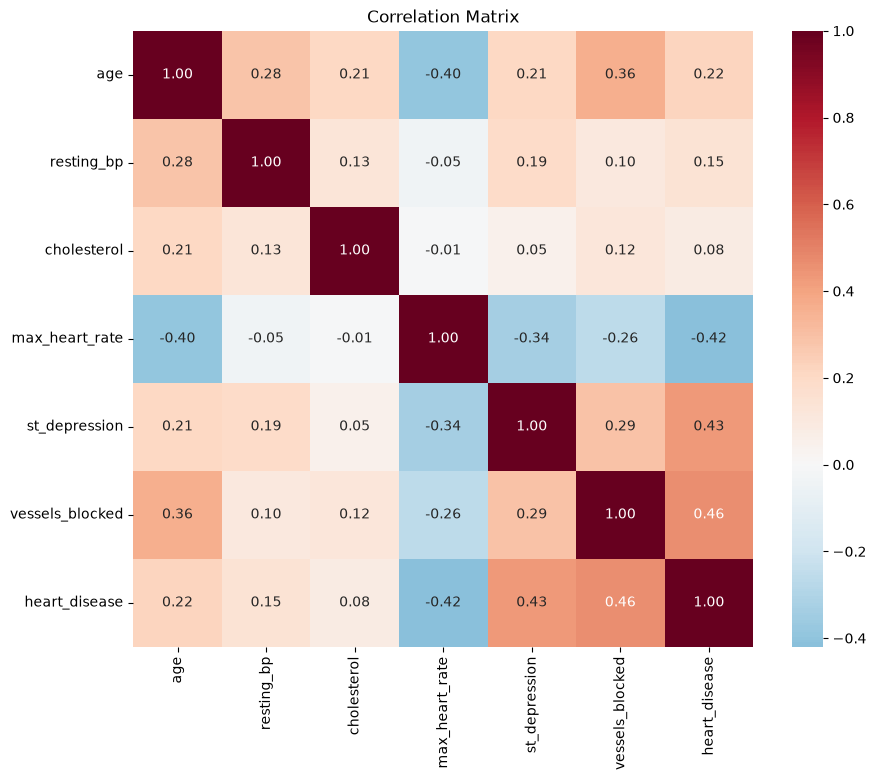

In [48]:
# Make a correlation matrix of the numeric columns
corr_matrix = df[["age", "resting_bp", "cholesterol", "max_heart_rate", "st_depression", "vessels_blocked", "heart_disease"]].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation Matrix");

### Answer to Problem 9
1. **Thallium scan (0.53)**, **chest-pain type (0.52)** and **vessels narrowed (0.49)** have the strongest link.
2. Stress-test measures come next (0.39–0.43).
3. Sex (0.28) and age (0.23) are moderate.
4. Routine checks are weakest (0.02–0.18). Blood pressure, cholesterol and blood sugar are not significant.

**Recommendation:** spend the diagnostic budget in this order: **symptoms → stress test → targeted imaging**.

## 13. Business Problem 10: Can we group patients into risk tiers?
Each patient gets 1 point for each of six warning signs:

| Warning sign | Rule |
|---|---|
| Silent chest pain | chest-pain type = Asymptomatic |
| Exercise angina | chest pain during exercise = Yes |
| ST depression | ST depression > 1 |
| Low max heart rate | max heart rate < 140 |
| Narrowed vessels | 1 or more vessels |
| Thallium defect | fixed or reversible defect |

Tiers: **0–1 signs = Low**, **2–3 = Medium**, **4–6 = High**.

> These tiers describe this data only. Test them on new patients before using them for real.

In [49]:
# 1 if the warning sign is present, 0 if not
df["sign_silent_chest_pain"] = (df["chest_pain_type"] == "Asymptomatic").astype(int)
df["sign_exercise_angina"] = (df["exercise_angina"] == "Yes").astype(int)
df["sign_st_depression"] = (df["st_depression"] > 1).astype(int)
df["sign_low_max_hr"] = (df["max_heart_rate"] < 140).astype(int)
df["sign_vessels_narrowed"] = (df["vessels_blocked"].fillna(0) >= 1).astype(int)
df["sign_thallium_defect"] = df["thallium_result"].isin(["Fixed defect", "Reversible defect"]).astype(int)

# Add up the signs for each patient
sign_cols = ["sign_silent_chest_pain", "sign_exercise_angina", "sign_st_depression",
             "sign_low_max_hr", "sign_vessels_narrowed", "sign_thallium_defect"]
df["warning_signs"] = df[sign_cols].sum(axis=1)

# Put patients into tiers
df["risk_tier"] = pd.cut(df["warning_signs"], bins=[-1, 1, 3, 6], labels=["Low", "Medium", "High"])
df[["patient_id", "warning_signs", "risk_tier", "diagnosis"]].head()

,patient_id,warning_signs,risk_tier,diagnosis
0,P001,2,Medium,No heart disease
1,P002,1,Low,No heart disease
2,P003,1,Low,No heart disease
3,P004,0,Low,No heart disease
4,P005,2,Medium,No heart disease


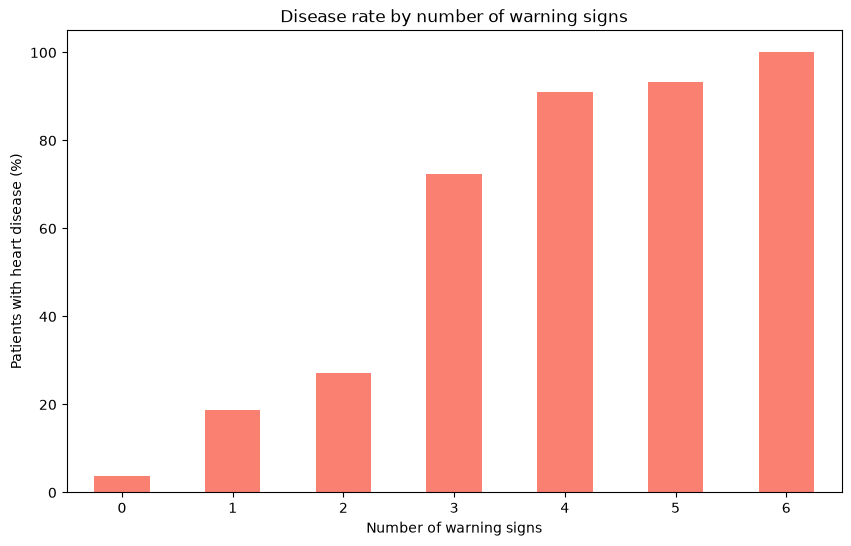

In [50]:
# Disease rate (%) by number of warning signs
signs_rate = df.groupby("warning_signs")["heart_disease"].mean() * 100
signs_rate.plot(kind="bar", color="salmon", figsize=(10, 6))
plt.title("Disease rate by number of warning signs")
plt.xlabel("Number of warning signs")
plt.ylabel("Patients with heart disease (%)")
plt.xticks(rotation=0);

In [51]:
# Summary table for each risk tier
tiers = df.groupby("risk_tier", observed=True)["heart_disease"].agg(["count", "sum"])
tiers.columns = ["patients", "with_disease"]
tiers["disease_rate_%"] = tiers["with_disease"] / tiers["patients"] * 100
tiers["share_of_patients_%"] = tiers["patients"] / len(df) * 100
tiers["share_of_all_disease_%"] = tiers["with_disease"] / df["heart_disease"].sum() * 100
tiers.round(1)

,patients,with_disease,disease_rate_%,share_of_patients_%,share_of_all_disease_%
risk_tier,,,,,
Low,122,15,12.3,40.4,10.9
Medium,88,37,42.0,29.1,26.8
High,92,86,93.5,30.5,62.3


### Answer to Problem 10
**Yes. Six simple warning signs split patients into clearly different groups.**

| Tier | Patients | Disease rate | Share of all disease cases |
|---|---|---|---|
| Low (0–1 signs) | 122 (40%) | **12%** | 11% |
| Medium (2–3 signs) | 88 (29%) | **42%** | 27% |
| High (4–6 signs) | 92 (30%) | **93%** | 62% |

The **High tier holds 62% of all cases in just 30% of patients**.

**Recommendation:**
* **High:** specialist review within days.
* **Medium:** stress test or imaging.
* **Low:** routine follow-up.

## 14. Export for Power BI
Save the 4 files the Power BI dashboard reads. They are written to `data/processed/`.

| File | What it holds | Dashboard page |
|---|---|---|
| `heart_disease_clean.csv` | One row per patient, with labels, bands, warning signs and risk tier | Pages 1–3 |
| `factor_ranking.csv` | The ranking from Problem 9 | Page 3 |
| `data_quality_log.csv` | What we found and fixed in Problem 1 | Page 4 |
| `data_dictionary.csv` | What each column means | Page 4 |

In [52]:
# Sort-order numbers, so Power BI shows the groups in a logical order instead of A-Z
orders = {"age_group": ["Under 40", "40-49", "50-59", "60-69", "70+"],
          "bp_category": ["Normal (<120)", "Elevated (120-129)", "Stage 1 (130-139)", "Stage 2 (140+)"],
          "cholesterol_category": ["Desirable (<200)", "Borderline (200-239)", "High (240+)"],
          "max_hr_band": ["Under 120", "120-139", "140-159", "160+"],
          "st_depression_band": ["None (0)", "Mild (0.1-1)", "Moderate (1.1-2)", "Severe (>2)"],
          "chest_pain_type": ["Typical angina", "Atypical angina", "Non-anginal pain", "Asymptomatic"],
          "resting_ecg": ["Normal", "ST-T abnormality", "LV hypertrophy"],
          "st_slope": ["Upsloping", "Flat", "Downsloping"],
          "thallium_result": ["Normal", "Fixed defect", "Reversible defect", "Unknown"],
          "risk_tier": ["Low", "Medium", "High"]}

for col, values in orders.items():
    df[col + "_order"] = df[col].astype(str).map({v: i + 1 for i, v in enumerate(values)})

df[["age_group", "age_group_order", "risk_tier", "risk_tier_order"]].head()

,age_group,age_group_order,risk_tier,risk_tier_order
0,60-69,4,Medium,2
1,Under 40,1,Low,1
2,40-49,2,Low,1
3,50-59,3,Low,1
4,50-59,3,Medium,2


In [53]:
# Choose the columns to export
export_cols = ["patient_id", "age", "age_group", "sex", "chest_pain_type", "resting_bp", "bp_category",
               "cholesterol", "cholesterol_category", "high_fasting_sugar", "resting_ecg", "max_heart_rate",
               "max_hr_band", "exercise_angina", "st_depression", "st_depression_band", "st_slope",
               "vessels_blocked", "vessels_label", "thallium_result"] + sign_cols + \
              ["warning_signs", "risk_tier", "heart_disease", "diagnosis", "original_target"] + \
              [col + "_order" for col in orders]

export = df[export_cols].copy()
export["vessels_blocked"] = export["vessels_blocked"].astype("Int64")   # whole numbers, blank = unknown

# Save the main table and the factor ranking
export.to_csv("../data/processed/heart_disease_clean.csv", index=False)
ranking.rename_axis("rank").to_csv("../data/processed/factor_ranking.csv")
print("Saved", export.shape[0], "patients and", export.shape[1], "columns")

Saved 302 patients and 41 columns


In [54]:
# Data quality log: what we found in Problem 1 and what we did about it
quality_log = pd.DataFrame({
    "issue": ["Duplicate rows", "Invalid 'ca' = 4", "Invalid 'thal' = 0", "Reversed outcome label",
              "Mis-documented codes (cp, restecg, slope, thal)", "Outliers (IQR rule)"],
    "rows_affected": [1,
                      (df_raw.drop_duplicates()["ca"] == 4).sum(),
                      (df_raw["thal"] == 0).sum(),
                      len(df),
                      len(df),
                      outliers.sum()],
    "action": ["Removed duplicate patient record", "Set to missing ('Unknown')", "Set to missing ('Unknown')",
               "heart_disease = 1 - target", "Re-labelled using UCI mapping", "Kept and flagged"],
    "note": ["302 unique patients", "Was '?' in UCI source", "Was '?' in UCI source",
             "Confirmed against UCI counts", "Confirmed against UCI counts", "All medically possible"],
})
quality_log.to_csv("../data/processed/data_quality_log.csv", index=False)
quality_log

,issue,rows_affected,action,note
0,Duplicate rows,1,Removed duplicate patient record,302 unique patients
1,Invalid 'ca' = 4,4,Set to missing ('Unknown'),Was '?' in UCI source
2,Invalid 'thal' = 0,2,Set to missing ('Unknown'),Was '?' in UCI source
3,Reversed outcome label,302,heart_disease = 1 - target,Confirmed against UCI counts
4,"Mis-documented codes (cp, restecg, slope, thal)",302,Re-labelled using UCI mapping,Confirmed against UCI counts
5,Outliers (IQR rule),20,Kept and flagged,All medically possible


In [55]:
# Data dictionary: what each column in the clean file means
data_dictionary = pd.DataFrame([
    ["patient_id", "Unique patient key"],
    ["age", "Age in years"],
    ["age_group", "10-year age band"],
    ["sex", "Male / Female"],
    ["chest_pain_type", "Typical angina, Atypical angina, Non-anginal pain, Asymptomatic"],
    ["resting_bp", "Resting blood pressure (mm Hg)"],
    ["bp_category", "AHA blood pressure stage"],
    ["cholesterol", "Serum cholesterol (mg/dl)"],
    ["cholesterol_category", "NCEP cholesterol band"],
    ["high_fasting_sugar", "Fasting blood sugar > 120 mg/dl (Yes/No)"],
    ["resting_ecg", "Resting ECG result"],
    ["max_heart_rate", "Maximum heart rate in stress test (bpm)"],
    ["max_hr_band", "Max heart rate band"],
    ["exercise_angina", "Chest pain during exercise (Yes/No)"],
    ["st_depression", "ST depression on exercise ECG"],
    ["st_depression_band", "ST depression severity band"],
    ["st_slope", "Slope of peak exercise ST segment"],
    ["vessels_blocked", "Major vessels narrowed on fluoroscopy (0-3, blank = unknown)"],
    ["vessels_label", "Vessels as text, incl. Unknown"],
    ["thallium_result", "Thallium scan result"],
    ["sign_*", "1 if the warning sign is present (see Problem 10)"],
    ["warning_signs", "Number of warning signs (0-6)"],
    ["risk_tier", "Low (0-1), Medium (2-3), High (4-6)"],
    ["heart_disease", "1 = heart disease, 0 = none (corrected)"],
    ["diagnosis", "Heart disease / No heart disease"],
    ["original_target", "Original label from the raw file (1 = no disease)"],
    ["*_order", "Sort-order number for the matching text column (use 'Sort by column' in Power BI)"],
], columns=["column", "description"])
data_dictionary.to_csv("../data/processed/data_dictionary.csv", index=False)
print("Saved all 4 files for Power BI: heart_disease_clean, factor_ranking, data_quality_log, data_dictionary")

Saved all 4 files for Power BI: heart_disease_clean, factor_ranking, data_quality_log, data_dictionary


## 15. Summary of findings

| # | Business problem | Key finding | Recommendation |
|---|---|---|---|
| 1 | Can we trust the data? | Outcome label reversed; 1 duplicate; 6 invalid codes | Validated data dictionary and automatic checks |
| 2 | How big is the problem? | 46% of 302 patients have heart disease | Use 46% as the baseline |
| 3 | Which ages? | 27% under 40, rising to 60% at 60–69 | Start screening at 50 |
| 4 | Men vs women? | Men 55% against women 25% | Screen men from 40–45, women from 50 |
| 5 | Chest-pain triage? | No chest pain has the highest rate (73%) | Fast-track silent patients |
| 6 | Routine checks? | BP, cholesterol and sugar barely separate patients | Don't use them as the referral gate |
| 7 | Stress test? | Strong signals, up to 86% | Use it early |
| 8 | Imaging? | Strongest signals (up to 85%) | Use it for patients already flagged |
| 9 | What matters most? | Thallium, chest pain, vessels, then the stress test | Symptoms → stress test → imaging |
| 10 | Risk tiers? | High tier: 93% disease, 62% of all cases | Prioritise follow-up by tier |

**Limitations:**
* Only 302 patients from one hospital (1988).
* The data shows links, not causes.
* The risk tiers need testing on new patients.

**Next:** the exported data feeds the Power BI dashboard (`powerbi/`) and the presentation (`presentation/`).